# Part 3: Logistic Regression

Run top to bottom. `FAST=0` runs at full scale (see README).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import mlcore as mc

FAST = mc.fast_mode()  # R2: FAST=0 for full scale
rng = np.random.default_rng(mc.SEED)  # R2 seed; experiments use mc.rng_for(tag)
print(f"FAST={FAST}")

FAST=True


## 3.2 Numerically stable logistic regression

$\theta(s)=\frac{1}{1+e^{-s}}$ is computed with `scipy.special.expit`, and $E_{in}(w)=\frac1N\sum_n\ln\!\left(1+e^{-y_nw^Tx_n}\right)$ with `np.logaddexp(0, -s)`, which evaluates $\ln(e^0+e^{-s})$ without forming $e^{-s}$ for large $|s|$.
The gradient uses $\theta(-y_nw^Tx_n)$, again via `expit`. Unit tests: `test_mlcore.py::test_logistic_stable` and `test_grad_logistic`.

In [2]:
import time
import warnings

s = np.array([-1000.0, -30.0, 0.0, 30.0, 1000.0])
X1, y1, w1 = np.array([[1.0], [1.0]]), np.array([1.0, -1.0]), np.array([1000.0])   # margins +1000 and -1000
with np.errstate(over="raise", invalid="raise", divide="raise", under="ignore"):     # underflow to 0 is harmless
    th = mc.theta(s)
    loss, grad = mc.logistic_loss_grad(w1, X1, y1)
print("theta(s) for s =", s, "->", th)
print(f"stable:  Ein = {loss} (exact: (ln(1 + e^-1000) + ln(1 + e^1000)) / 2 = 500), gradient = {grad}")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    naive = np.mean(np.log(1 + np.exp(-y1 * (X1 @ w1))))
print(f"naive:   Ein = {naive} with {len(caught)} warning(s): {[str(c.message) for c in caught]}")
assert np.isfinite(loss) and np.all(np.isfinite(grad)) and not np.isfinite(naive)

theta(s) for s = [-1000.   -30.     0.    30.  1000.] -> [0.00000000e+00 9.35762297e-14 5.00000000e-01 1.00000000e+00
 1.00000000e+00]
stable:  Ein = 500.0 (exact: (ln(1 + e^-1000) + ln(1 + e^1000)) / 2 = 500), gradient = [0.5]
naive:   Ein = inf with 1 warning(s): ['overflow encountered in exp']


**Interpretation.** At $s=\pm1000$ the stable versions return exact values without warnings ($E_{in}=500$), while the naive formula overflows to `inf`. `logaddexp` and `expit` never form $e^{1000}$.

## 3.3 Three optimizers

All three minimize the same cross-entropy $E_{in}$:
- **batch GD**: full gradient, constant $\eta$;
- **SGD**: one point at a time, in a fresh random order each epoch (`mc.sgd_logistic`);
- **L-BFGS**: `scipy.optimize.minimize(method="L-BFGS-B")` with our analytic gradient (`mc.lbfgs`).

Data: $d=2$, $x\sim U[-1,1]^2$, target line through two random points, $N=100$ (`mc.random_linear_target`, `mc.linear_target_data`).
(a) uses the clean (separable) labels as stated. (b) and (c) flip 10% of the labels so that a finite optimum exists (DECISIONS row 3).

In [3]:
# 3.3(a) SGD, eta = 0.01, 100 runs
RUNS_33 = 100
rng = mc.rng_for("3_3a")
epochs, eout_ce, eout_01, wnorm = [], [], [], []
t0 = time.perf_counter()
for _ in range(RUNS_33):
    w_t = mc.random_linear_target(rng)
    X, y_clean, _ = mc.linear_target_data(rng, 100, w_t)
    w, ep, _ = mc.sgd_logistic(X, y_clean, rng, 0.01, 100_000, tol=0.01)
    assert ep is not None
    Xt, yt, _ = mc.linear_target_data(rng, 10_000, w_t)
    epochs.append(ep), eout_ce.append(mc.logistic_loss_grad(w, Xt, yt)[0]), eout_01.append(mc.ein_01(w, Xt, yt))
    wnorm.append(np.linalg.norm(w))
m, se = mc.mean_se(epochs)
print(f"{RUNS_33} runs in {time.perf_counter() - t0:.1f} s")
print(f"epochs to stop:          {m:.1f} ± {se:.1f}  (min {min(epochs)}, median {np.median(epochs):.0f}, max {max(epochs)})")
print("cross-entropy Eout:      {:.4f} ± {:.4f}".format(*mc.mean_se(eout_ce)))
print("classification Eout:     {:.4f} ± {:.4f}".format(*mc.mean_se(eout_01)))
print("||w|| at stop:           {:.2f} ± {:.2f}".format(*mc.mean_se(wnorm)))

100 runs in 9.2 s
epochs to stop:          333.2 ± 4.6  (min 125, median 338, max 434)
cross-entropy Eout:      0.1022 ± 0.0012
classification Eout:     0.0193 ± 0.0012
||w|| at stop:           8.91 ± 0.11


**Interpretation.** Over 100 runs SGD stops after $333\pm5$ epochs, with cross-entropy $E_{out}=0.102\pm0.001$ and classification error $0.019\pm0.001$. The data are separable, so the stopping rule, not convergence to an optimum, ends each run.

In [4]:
# 3.3(b) GD step sizes on noisy data
rng = mc.rng_for("3_3b")
w_t = mc.random_linear_target(rng)
X, _, y = mc.linear_target_data(rng, 100, w_t, flip=0.1)
lg = lambda w: mc.logistic_loss_grad(w, X, y)  # noqa: E731
L = mc.lipschitz_logistic(X)
w_star, res = mc.lbfgs(lg, np.zeros(3))
E_star = res.fun
margin = y * (X @ w_star)
H = (X.T * (mc.theta(margin) * mc.theta(-margin))) @ X / X.shape[0]   # Hessian of Ein at w*
lam_loc = np.linalg.eigvalsh(H).max()
print(f"global bound: L = 0.25 * lambda_max(X^T X / N) = {L:.4f}  ->  2/L = {2 / L:.2f}")
print(f"local curvature at w*: lambda_max(Hessian) = {lam_loc:.4f}  ->  2/lambda_loc = {2 / lam_loc:.2f}")
print(f"optimum E* = {E_star:.6f} (L-BFGS, {res.nit} iterations)")

ETAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
ETAS_EXT = [30.0, 100.0]               # beyond the brief's grid (DECISIONS row 15)
hists = {}
for eta in ETAS + ETAS_EXT:
    hists[eta] = mc.gradient_descent(lg, np.zeros(3), eta, 2000)[1]
    h = hists[eta]
    print(f"eta = {eta:>6g}: Ein after 10 / 100 / 2000 iterations = {h[10]:.5f} / {h[100]:.5f} / {h[-1]:.6f}; "
          f"gap to E* {h[-1] - E_star:.1e}; increases > 1e-9: {np.sum(np.diff(h) > 1e-9)}")
assert all(np.all(np.isfinite(h)) for h in hists.values())

global bound: L = 0.25 * lambda_max(X^T X / N) = 0.2529  ->  2/L = 7.91
local curvature at w*: lambda_max(Hessian) = 0.1349  ->  2/lambda_loc = 14.83
optimum E* = 0.414484 (L-BFGS, 11 iterations)
eta =  0.001: Ein after 10 / 100 / 2000 iterations = 0.69280 / 0.68972 / 0.634987; gap to E* 2.2e-01; increases > 1e-9: 0
eta =   0.01: Ein after 10 / 100 / 2000 iterations = 0.68972 / 0.66154 / 0.466262; gap to E* 5.2e-02; increases > 1e-9: 0
eta =    0.1: Ein after 10 / 100 / 2000 iterations = 0.66142 / 0.51856 / 0.414560; gap to E* 7.6e-05; increases > 1e-9: 0
eta =      1: Ein after 10 / 100 / 2000 iterations = 0.51597 / 0.41619 / 0.414484; gap to E* 0.0e+00; increases > 1e-9: 0
eta =     10: Ein after 10 / 100 / 2000 iterations = 0.41534 / 0.41448 / 0.414484; gap to E* 0.0e+00; increases > 1e-9: 0
eta =     30: Ein after 10 / 100 / 2000 iterations = 0.53057 / 1.05218 / 0.857432; gap to E* 4.4e-01; increases > 1e-9: 992
eta =    100: Ein after 10 / 100 / 2000 iterations = 1.36787 / 1.66187

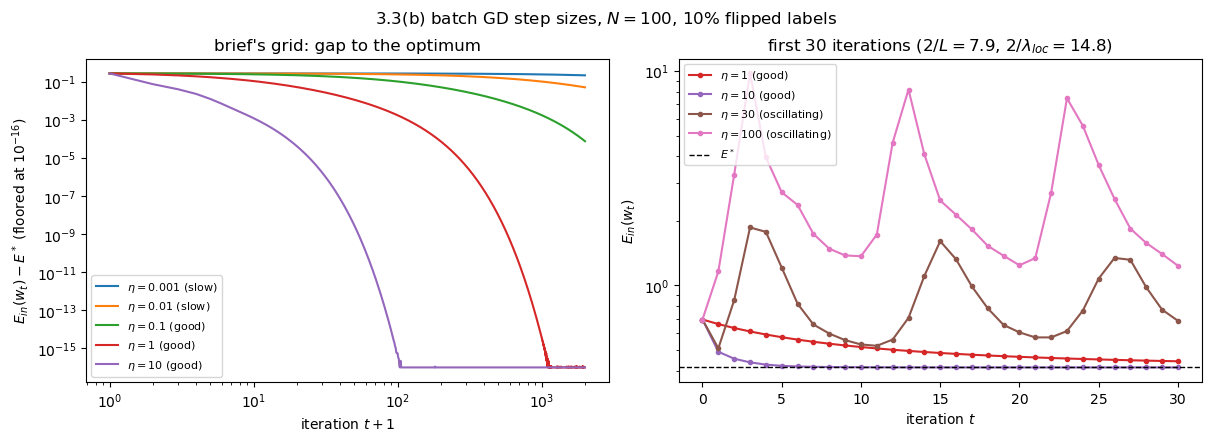

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
regime = {1e-3: "slow", 1e-2: "slow", 1e-1: "good", 1.0: "good", 10.0: "good", 30.0: "oscillating", 100.0: "oscillating"}
ax = axes[0]
for c, eta in enumerate(ETAS):
    h = hists[eta]
    ax.loglog(np.arange(1, h.size + 1), np.maximum(h - E_star, 1e-16), color=f"C{c}", label=rf"$\eta = {eta:g}$ ({regime[eta]})")
ax.set(xlabel="iteration $t + 1$", ylabel=r"$E_{in}(w_t) - E^*$ (floored at $10^{-16}$)", title="brief's grid: gap to the optimum")
ax.legend(fontsize=8)
ax = axes[1]
for c, eta in enumerate([1.0, 10.0, 30.0, 100.0]):
    ax.plot(np.arange(31), hists[eta][:31], "o-", ms=3, color=f"C{c + 3}", label=rf"$\eta = {eta:g}$ ({regime[eta]})")
ax.axhline(E_star, color="k", ls="--", lw=1, label="$E^*$")
ax.set(yscale="log", xlabel="iteration $t$", ylabel="$E_{in}(w_t)$",
       title=rf"first 30 iterations ($2/L = {2 / L:.1f}$, $2/\lambda_{{loc}} = {2 / lam_loc:.1f}$)")
ax.legend(fontsize=8)
fig.suptitle(r"3.3(b) batch GD step sizes, $N = 100$, 10% flipped labels")
mc.savefig(fig, "3_3b_step_sizes")
plt.show()

**Interpretation.** With 10% flipped labels ($E^*=0.4145$), $\eta=10^{-3}$ and $10^{-2}$ are still 0.22 and 0.052 above $E^*$ after 2000 iterations (slow), $\eta=0.1$ to 10 converge (good), and $\eta=30$ and 100 oscillate (992 and 597 increases). $\eta=10$ converges although it exceeds the global bound $2/L=7.9$, because the curvature at the optimum allows up to $2/\lambda_{loc}=14.8$ (DECISIONS row 15).

GD, eta = 1/L = 3.95   median      0.86 ms |     85 iterations | gap 8.9e-07 (reached 1e-6)
GD, eta = 10           median      0.32 ms |     31 iterations | gap 8.9e-07 (reached 1e-6)


SGD, eta = 0.01        median     99.35 ms |    344 epochs     | gap 1.0e-06 (reached 1e-6)


SGD, eta = 0.1         median    432.60 ms |   1494 epochs     | gap 5.7e-07 (reached 1e-6)
L-BFGS                 median      0.31 ms |     11 iterations | gap 0.0e+00 (reached 1e-6)


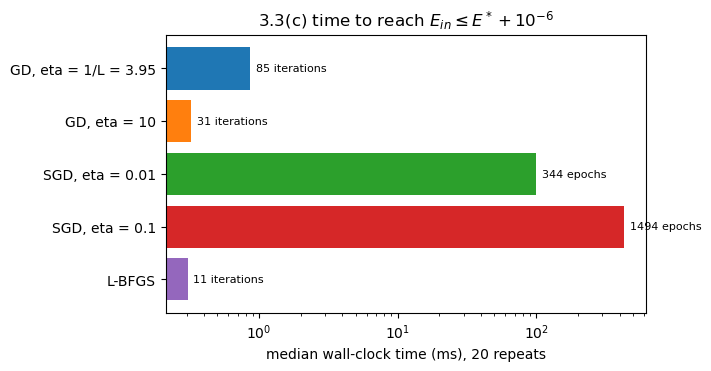

In [6]:
# 3.3(c) time to E* + 1e-6, median of 20
f_target = E_star + 1e-6
REPEATS_33C = 20


def run_gd(eta):
    w, h = mc.gradient_descent(lg, np.zeros(3), eta, 10**6, f_stop=f_target)
    return h[-1], h.size - 1, "iterations"


def run_sgd(eta):
    w, n_ep, h = mc.sgd_logistic(X, y, mc.rng_for("3_3c_sgd"), eta, 20_000, f_stop=f_target)
    return h[-1], (n_ep if n_ep is not None else -1), "epochs"


def run_lbfgs():
    w, r = mc.lbfgs(lg, np.zeros(3))
    return r.fun, r.nit, "iterations"


CONTENDERS = {
    f"GD, eta = 1/L = {1 / L:.2f}": lambda: run_gd(1 / L),
    "GD, eta = 10": lambda: run_gd(10.0),
    "SGD, eta = 0.01": lambda: run_sgd(0.01),
    "SGD, eta = 0.1": lambda: run_sgd(0.1),
    "L-BFGS": run_lbfgs,
}
race = {}
for name, fn in CONTENDERS.items():
    final, count, unit = fn()                      # warm-up, also gives the counts
    times = []
    for _ in range(REPEATS_33C):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    race[name] = (np.median(times), count, unit, final - E_star)
    reached = "reached" if final <= f_target else "did NOT reach"
    print(f"{name:<22} median {np.median(times) * 1e3:9.2f} ms | {count:>6} {unit:<10} | gap {final - E_star:.1e} ({reached} 1e-6)")

fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
names = list(race)
ax.barh(names, [race[n][0] * 1e3 for n in names], color=[f"C{i}" for i in range(len(names))])
for i, n in enumerate(names):
    ax.text(race[n][0] * 1e3 * 1.1, i, f"{race[n][1]} {race[n][2]}", va="center", fontsize=8)
ax.set(xscale="log", xlabel="median wall-clock time (ms), 20 repeats", title=r"3.3(c) time to reach $E_{in} \leq E^* + 10^{-6}$")
ax.invert_yaxis()
mc.savefig(fig, "3_3c_wallclock")
plt.show()

**Interpretation.** To reach $E^*+10^{-6}$, L-BFGS needs 11 iterations (about 0.3 ms) and GD 31 at $\eta=10$ (about 0.3 ms) or 85 at $\eta=1/L$. SGD needs 344 epochs at $\eta=0.01$ (about 0.1 s) and 1494 at $\eta=0.1$, because its gradient noise sets a floor that grows with $\eta$.

## 3.4 ⋆ When the data are separable

Unregularized batch GD ($\eta=1/L$) for $10^5$ iterations on linearly separable data ($N=100$, $d=2$). We track $\lVert w_t\rVert$, $E_{in}(w_t)$ and the angle between $w_t$ and $w_{t+1000}$, then repeat with weight decay $\lambda=10^{-3}$ in the $E_{in}+\lambda\lVert w\rVert^2$ form (DECISIONS row 17).
The $E_{in}$ curves are always the *unpenalized* cross-entropy, so both runs share the same scale.
Reference: Soudry, Hoffer, Nacson, Gunasekar, Srebro, *The Implicit Bias of Gradient Descent on Separable Data*, JMLR 19(70), 2018.

In [7]:
rng = mc.rng_for("3_4")
w_t = mc.random_linear_target(rng)
X4, y4, _ = mc.linear_target_data(rng, 100, w_t)
assert mc.ein_01(w_t, X4, y4) == 0.0                      # linearly separable by construction
T, LAG = 100_000, 1000
runs34 = {}
t0 = time.perf_counter()
for lam in (0.0, 1e-3):
    eta = 1 / mc.lipschitz_logistic(X4, lam)
    W, E = np.empty((T + 1, 3)), np.empty(T + 1)
    w = np.zeros(3)
    for t in range(T + 1):
        W[t] = w
        f, g = mc.logistic_loss_grad(w, X4, y4, lam)
        E[t] = mc.logistic_loss_grad(w, X4, y4)[0] if lam else f
        w = w - eta * g
    norms = np.linalg.norm(W, axis=1)
    cos = np.sum(W[1:T - LAG + 1] * W[1 + LAG:], axis=1) / (norms[1:T - LAG + 1] * norms[1 + LAG:])
    runs34[lam] = {"W": W, "E": E, "norm": norms, "angle": np.degrees(np.arccos(np.clip(cos, -1, 1)))}   # angle[t-1] is for t
print(f"2 x {T} GD iterations in {time.perf_counter() - t0:.1f} s")
for lam, r in runs34.items():
    print(f"\nlambda = {lam:g}")
    for t in (10**3, 10**4, 5 * 10**4, T - LAG):
        p_min = mc.theta(y4 * (X4 @ r["W"][t])).min()
        print(f"  t = {t:>6}: ||w|| = {r['norm'][t]:8.3f}  Ein = {r['E'][t]:.5f}  angle(w_t, w_t+1000) = {r['angle'][t - 1]:.2e} deg"
              f"  min_n theta(y_n w^T x_n) = {p_min:.5f}")
r = runs34[0.0]
t_fit = np.arange(10**4, T + 1)
slope_norm = np.polyfit(np.log(t_fit), r["norm"][t_fit], 1)[0]
slope_ein = np.polyfit(np.log(t_fit), np.log(r["E"][t_fit]), 1)[0]
print(f"\nlambda = 0, t in [1e4, 1e5]: d||w||/d(ln t) = {slope_norm:.1f}; log-log slope of Ein vs t = {slope_ein:.3f} "
      f"(asymptotic theory: ||w|| ~ ln(t)/gamma, Ein ~ 1/t, slope -1)")
print(f"direction at t = {T}: w/||w|| = {np.round(r['W'][T] / r['norm'][T], 4)}; target w_t/||w_t|| = {np.round(w_t / np.linalg.norm(w_t), 4)}")

2 x 100000 GD iterations in 2.3 s

lambda = 0
  t =   1000: ||w|| =   23.047  Ein = 0.04513  angle(w_t, w_t+1000) = 1.71e-01 deg  min_n theta(y_n w^T x_n) = 0.51964
  t =  10000: ||w|| =   48.488  Ein = 0.02231  angle(w_t, w_t+1000) = 8.01e-03 deg  min_n theta(y_n w^T x_n) = 0.53744
  t =  50000: ||w|| =   80.351  Ein = 0.01537  angle(w_t, w_t+1000) = 5.62e-04 deg  min_n theta(y_n w^T x_n) = 0.57473
  t =  99000: ||w|| =  101.708  Ein = 0.01300  angle(w_t, w_t+1000) = 1.26e-04 deg  min_n theta(y_n w^T x_n) = 0.59006

lambda = 0.001
  t =   1000: ||w|| =    8.366  Ein = 0.12049  angle(w_t, w_t+1000) = 0.00e+00 deg  min_n theta(y_n w^T x_n) = 0.47481
  t =  10000: ||w|| =    8.366  Ein = 0.12049  angle(w_t, w_t+1000) = 0.00e+00 deg  min_n theta(y_n w^T x_n) = 0.47481
  t =  50000: ||w|| =    8.366  Ein = 0.12049  angle(w_t, w_t+1000) = 0.00e+00 deg  min_n theta(y_n w^T x_n) = 0.47481
  t =  99000: ||w|| =    8.366  Ein = 0.12049  angle(w_t, w_t+1000) = 0.00e+00 deg  min_n theta(y_n w^T x

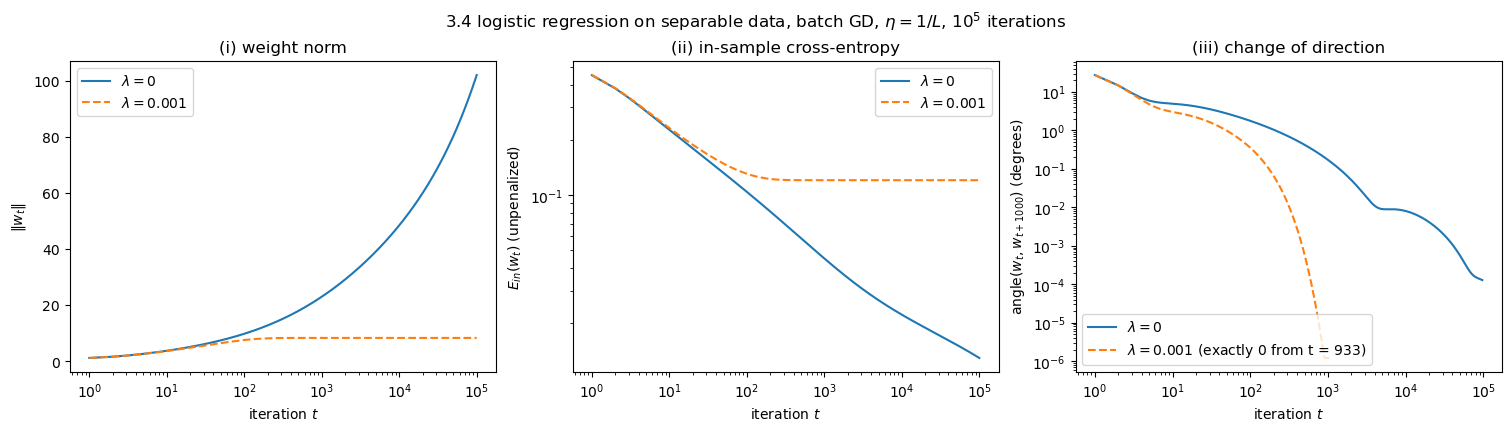

In [8]:
idx = np.unique(np.logspace(0, 5, 400).astype(int))
idx_a = idx[idx <= T - LAG]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for lam, ls in ((0.0, "-"), (1e-3, "--")):
    r = runs34[lam]
    lab = r"$\lambda = 0$" if lam == 0 else rf"$\lambda = {lam:g}$"
    axes[0].semilogx(idx, r["norm"][idx], ls, label=lab)
    axes[1].loglog(idx, r["E"][idx], ls, label=lab)
    ang = r["angle"][idx_a - 1]
    pos = ang > 0                                          # angle is 0 once the L2 run converges
    axes[2].loglog(idx_a[pos], ang[pos], ls, label=lab + ("" if pos.all() else f" (exactly 0 from t = {idx_a[~pos][0]})"))
axes[0].set(xlabel="iteration $t$", ylabel=r"$\Vert w_t \Vert$", title=r"(i) weight norm")
axes[1].set(xlabel="iteration $t$", ylabel=r"$E_{in}(w_t)$ (unpenalized)", title=r"(ii) in-sample cross-entropy")
axes[2].set(xlabel="iteration $t$", ylabel=r"angle$(w_t, w_{t+1000})$ (degrees)", title=r"(iii) change of direction")
for ax in axes:
    ax.legend()
fig.suptitle(r"3.4 logistic regression on separable data, batch GD, $\eta = 1/L$, $10^5$ iterations")
mc.savefig(fig, "3_4_separable")
plt.show()

**Interpretation.** Without a penalty $\lVert w_t\rVert$ grows from 23 to 102 and $E_{in}$ keeps falling (0.045 to 0.013): separable data have no finite minimizer, and the probabilities move towards 0 and 1. The direction still settles, with the angle between $w_t$ and $w_{t+1000}$ shrinking from 0.17° to $1.3\times10^{-4}$°, towards the max-margin separator. With $\lambda=10^{-3}$ the norm stops at 8.37 and $E_{in}$ at 0.120.

## 3.5 Real data: breast cancer

Malignant (target 0) is $y=+1$. Stratified 70/30 split (tag `3_5_split`, shared with 3.6), standardization on the training split. The training split is separable, so we use L2 logistic regression with $\lambda$ from 10-fold CV of the cross-entropy (DECISIONS row 22).

In [9]:
from sklearn.datasets import load_breast_cancer   # data loading only (R1)

bc = load_breast_cancer()
yb = np.where(bc.target == 0, 1.0, -1.0)            # malignant (target 0) -> +1
tr35, te35 = mc.stratified_split(yb, 0.3, mc.rng_for("3_5_split"))
print(f"train {tr35.size} ({np.sum(yb[tr35] == 1)} malignant), test {te35.size} ({np.sum(yb[te35] == 1)} malignant)")


def fit_l2(X, y, lam):
    return mc.lbfgs(lambda v: mc.logistic_loss_grad(v, X, y, lam), np.zeros(X.shape[1]))[0]


def l2_fp(lams):
    def fp(P_tr, y_tr, P_val):
        Z_tr, prm = mc.standardize(P_tr)                 # refitted inside each fold
        Xtr, Xval = mc.add_bias(Z_tr), mc.add_bias(mc.apply_standardize(P_val, prm))
        return np.array([Xval @ fit_l2(Xtr, y_tr, lam) for lam in lams])
    return fp


LAM35 = np.logspace(0, -5, 21)                        # decreasing: ties go to the larger lambda
folds35 = mc.kfold_indices(tr35.size, 10, mc.rng_for("3_5_cv"))
cv_ce, _ = mc.cv_curve(l2_fp(LAM35), bc.data[tr35], yb[tr35], folds35, loss="logistic")
cv_01, _ = mc.cv_curve(l2_fp(LAM35), bc.data[tr35], yb[tr35], folds35, loss="01")
k35 = int(np.argmin(cv_ce))
lam35 = LAM35[k35]
print(f"lambda* = {lam35:.3g} (10-fold CV cross-entropy {cv_ce[k35]:.4f}, CV error {cv_01[k35]:.4f}); "
      f"at lambda = {LAM35[-1]:.0e} the CV cross-entropy is {cv_ce[-1]:.4f}")

Z35, prm35 = mc.standardize(bc.data[tr35])
X35, y35 = mc.add_bias(Z35), yb[tr35]
w35 = fit_l2(X35, y35, lam35)
print(f"training error {mc.ein_01(w35, X35, y35):.4f}, ||w|| = {np.linalg.norm(w35[1:]):.2f}")

train 398 (148 malignant), test 171 (64 malignant)


lambda* = 0.00178 (10-fold CV cross-entropy 0.0659, CV error 0.0176); at lambda = 1e-05 the CV cross-entropy is 0.3176
training error 0.0050, ||w|| = 3.21


In [10]:
# TEST: evaluated once (threshold 0.5)
X35te, y35te = mc.add_bias(mc.apply_standardize(bc.data[te35], prm35)), yb[te35]
p35 = mc.logistic_proba(w35, X35te)
yhat35 = np.where(p35 >= 0.5, 1, -1)
rep35 = mc.classification_report(y35te, yhat35, pos=1)
for k in ("accuracy", "precision", "recall", "f1"):
    print(f"{k:<10} {rep35[k]:.4f}")
print("confusion matrix [[TP, FN], [FP, TN]] (malignant = positive):\n", rep35["confusion"])
fpr35, tpr35, thr35 = mc.roc_curve(y35te, p35, pos=1)
auc35 = mc.auc(fpr35, tpr35)
print(f"AUC = {auc35:.4f}")

accuracy   0.9532
precision  0.9667
recall     0.9062
f1         0.9355
confusion matrix [[TP, FN], [FP, TN]] (malignant = positive):
 [[ 58   6]
 [  2 105]]
AUC = 0.9936


**3.5(b) Choosing the threshold for recall ≥ 0.98.** A stratified 25% validation split is carved from the training split (tag `3_5_val`); the test set is not involved. The model is refitted on the remaining 75%, with standardization fitted there and the same $\lambda^*$.
A tumour is called malignant when $\theta(w^Tx)\ge t$. We pick the **largest** $t$ whose validation recall is at least 0.98, because the largest such $t$ gives the fewest false alarms. Then we evaluate that model once on the test set, at $t$ and at 0.5.

validation: 99 points, 37 malignant (one miss costs 0.027 of recall)
chosen threshold t* = 0.1049: validation recall 1.000, precision 0.902
test at threshold t*  = 0.1049: recall 0.953, precision 0.859, missed malignant 3, false alarms 10
test at threshold 0.5 = 0.5000: recall 0.922, precision 0.983, missed malignant 5, false alarms 1


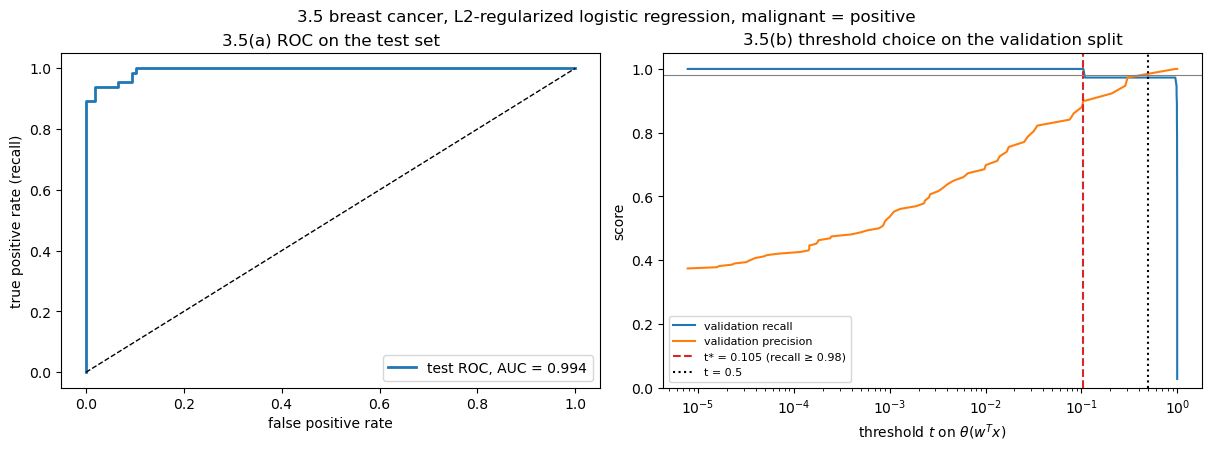

In [11]:
sub_tr, val = mc.stratified_split(y35, 0.25, mc.rng_for("3_5_val"))
Zs, prms = mc.standardize(bc.data[tr35][sub_tr])
Xs, ys = mc.add_bias(Zs), y35[sub_tr]
ws = fit_l2(Xs, ys, lam35)
Xval, yval = mc.add_bias(mc.apply_standardize(bc.data[tr35][val], prms)), y35[val]
pval = mc.logistic_proba(ws, Xval)
cands = np.unique(pval)[::-1]                          # every distinct score is a candidate threshold
rec_v = np.array([mc.recall(yval, np.where(pval >= t, 1, -1)) for t in cands])
prec_v = np.array([mc.precision(yval, np.where(pval >= t, 1, -1)) for t in cands])
t_star = cands[np.argmax(rec_v >= 0.98)]               # first (largest) threshold reaching the target
n_pos_val = int(np.sum(yval == 1))
print(f"validation: {val.size} points, {n_pos_val} malignant (one miss costs {1 / n_pos_val:.3f} of recall)")
print(f"chosen threshold t* = {t_star:.4f}: validation recall {mc.recall(yval, np.where(pval >= t_star, 1, -1)):.3f}, "
      f"precision {mc.precision(yval, np.where(pval >= t_star, 1, -1)):.3f}")

# TEST: evaluated once (thresholds t* and 0.5)
ps_te = mc.logistic_proba(ws, mc.add_bias(mc.apply_standardize(bc.data[te35], prms)))
for name, t in (("t*", t_star), ("0.5", 0.5)):
    yh = np.where(ps_te >= t, 1, -1)
    cm = mc.confusion_matrix(y35te, yh)
    print(f"test at threshold {name:<3} = {t:.4f}: recall {mc.recall(y35te, yh):.3f}, precision {mc.precision(y35te, yh):.3f}, "
          f"missed malignant {cm[0, 1]}, false alarms {cm[1, 0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
ax = axes[0]
ax.plot(fpr35, tpr35, lw=2, label=f"test ROC, AUC = {auc35:.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="3.5(a) ROC on the test set")
ax.legend()
ax = axes[1]
ax.plot(cands, rec_v, label="validation recall")
ax.plot(cands, prec_v, label="validation precision")
ax.axvline(t_star, color="C3", ls="--", label=f"t* = {t_star:.3f} (recall ≥ 0.98)")
ax.axvline(0.5, color="k", ls=":", label="t = 0.5")
ax.axhline(0.98, color="gray", lw=0.8)
ax.set(xscale="log", xlabel=r"threshold $t$ on $\theta(w^Tx)$", ylabel="score", ylim=(0, 1.05), title="3.5(b) threshold choice on the validation split")
ax.legend(fontsize=8)
fig.suptitle("3.5 breast cancer, L2-regularized logistic regression, malignant = positive")
mc.savefig(fig, "3_5_roc_threshold")
plt.show()

**Interpretation.** CV picks $\lambda^*=0.00178$; at $\lambda=10^{-5}$ the CV cross-entropy is five times larger (0.318 against 0.066), because a weak penalty makes the probabilities overconfident. At threshold 0.5 the test set gives accuracy 0.953, precision 0.967, recall 0.906 (6 of 64 cancers missed) and AUC 0.994. The validation threshold $t^*=0.105$ raises test recall to 0.953 at precision 0.859. A threshold of 0.5 is a poor default here, since a missed cancer costs far more than a false alarm (DECISIONS row 22).

## 3.6 Library comparison

scikit-learn minimizes $C\sum_n\ln(1+e^{-y_nw^Tx_n})+\frac12\lVert\tilde w\rVert^2$ (intercept not penalized). We minimize $\frac1N\sum_n\ln(1+e^{-y_nw^Tx_n})+\lambda\lVert\tilde w\rVert^2$, also with the bias unpenalized.
Multiplying ours by $NC>0$ (which does not move the minimizer) and matching the penalty terms gives $NC\lambda=\frac12$, i.e. $C=\frac{1}{2N\lambda}$, where $N$ is the training-set size.
Derivation: report, Section II; verified numerically below.
Data: the 3.3 noisy simulated set for `penalty=None`, and the breast-cancer training split for the $\lambda$ grid (DECISIONS row 18). The breast-cancer training split is linearly separable, so an unpenalized fit has no finite optimum there (cf. 3.4).

In [12]:
# Library comparison: penalty=None and default C
from sklearn.linear_model import LogisticRegression

N = X.shape[0]
sk = LogisticRegression(penalty=None, tol=1e-12, max_iter=100_000).fit(X[:, 1:], y)
w_sk = np.r_[sk.intercept_, sk.coef_.ravel()]
diff_none = np.max(np.abs(w_star - w_sk))
print(f"simulated N = {N}, penalty=None: max|w_ours - w_sklearn| = {diff_none:.1e}")
assert diff_none < 1e-5

default = LogisticRegression().fit(X[:, 1:], y)            # default: C = 1.0, tol = 1e-4, max_iter = 100
w_def = np.r_[default.intercept_, default.coef_.ravel()]
lam_def = 1 / (2 * N * 1.0)
w_lam_def = mc.lbfgs(lambda w: mc.logistic_loss_grad(w, X, y, lam_def), np.zeros(3))[0]
print(f"default LogisticRegression() vs our UNPENALIZED fit: max|dw| = {np.max(np.abs(w_def - w_star)):.3f}  (the pitfall: C = 1 is regularized)")
print(f"default LogisticRegression() vs our lambda = 1/(2N) = {lam_def}: max|dw| = {np.max(np.abs(w_def - w_lam_def)):.1e}  (left: tol = 1e-4)")
sim_rows = []
for lam in (1e-4, 1e-3, 1e-2, 1e-1):
    w_o = mc.lbfgs(lambda w: mc.logistic_loss_grad(w, X, y, lam), np.zeros(3))[0]
    fits = {}
    for tol in (1e-12, 1e-4):
        m = LogisticRegression(C=1 / (2 * N * lam), tol=tol, max_iter=100_000).fit(X[:, 1:], y)
        fits[tol] = np.max(np.abs(w_o - np.r_[m.intercept_, m.coef_.ravel()]))
    sim_rows.append((lam, fits[1e-12], fits[1e-4]))
    print(f"simulated lambda = {lam:g} (C = {1 / (2 * N * lam):g}): max|dw| tight tol {fits[1e-12]:.1e}, default tol {fits[1e-4]:.1e}")

simulated N = 100, penalty=None: max|w_ours - w_sklearn| = 8.8e-10
default LogisticRegression() vs our UNPENALIZED fit: max|dw| = 1.111  (the pitfall: C = 1 is regularized)
default LogisticRegression() vs our lambda = 1/(2N) = 0.005: max|dw| = 1.4e-03  (left: tol = 1e-4)
simulated lambda = 0.0001 (C = 50): max|dw| tight tol 3.3e-09, default tol 3.1e-05
simulated lambda = 0.001 (C = 5): max|dw| tight tol 6.5e-07, default tol 9.3e-04
simulated lambda = 0.01 (C = 0.5): max|dw| tight tol 4.3e-08, default tol 4.3e-04
simulated lambda = 0.1 (C = 0.05): max|dw| tight tol 1.1e-10, default tol 3.4e-04


label mapping: malignant (target 0) -> +1: 148 training points; benign -> -1: 250
training split N = 398; test split (171 points) is not used here
lambda = 0.0001: C = 12.56 | max|dw| tight tol 9.5e-05 (relative 2.0e-05) | default tol 9.3e-02 | ours: 78 L-BFGS iterations
lambda = 0.001: C = 1.256 | max|dw| tight tol 3.7e-06 (relative 2.5e-06) | default tol 2.0e-02 | ours: 38 L-BFGS iterations
lambda = 0.01: C = 0.1256 | max|dw| tight tol 8.3e-07 (relative 1.5e-06) | default tol 1.6e-03 | ours: 20 L-BFGS iterations
lambda = 0.1: C = 0.01256 | max|dw| tight tol 2.8e-07 (relative 4.6e-07) | default tol 2.6e-04 | ours: 13 L-BFGS iterations


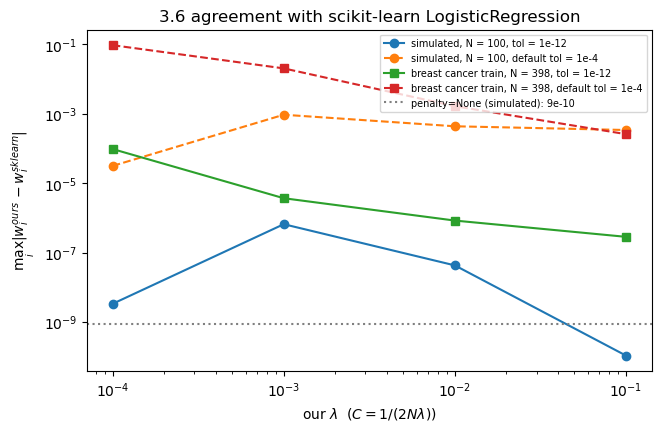

In [13]:
# Library comparison: C = 1/(2 N lambda)
from sklearn.datasets import load_breast_cancer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

bc = load_breast_cancer()
yb = np.where(bc.target == 0, 1.0, -1.0)                   # target 0 = malignant -> +1 (positive class)
tr, te = mc.stratified_split(yb, 0.3, mc.rng_for("3_5_split"))
Z, params = mc.standardize(bc.data[tr])                    # training statistics only
Xtr, ytr, Ntr = mc.add_bias(Z), yb[tr], tr.size
print(f"label mapping: malignant (target 0) -> +1: {np.sum(ytr == 1)} training points; benign -> -1: {np.sum(ytr == -1)}")
print(f"training split N = {Ntr}; test split ({te.size} points) is not used here")
bc_rows = []
for lam in (1e-4, 1e-3, 1e-2, 1e-1):
    w_o, r_o = mc.lbfgs(lambda w: mc.logistic_loss_grad(w, Xtr, ytr, lam), np.zeros(Xtr.shape[1]))
    C = 1 / (2 * Ntr * lam)
    tight = LogisticRegression(C=C, tol=1e-12, max_iter=100_000).fit(Xtr[:, 1:], ytr)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        dflt = LogisticRegression(C=C).fit(Xtr[:, 1:], ytr)
    d_t = np.max(np.abs(w_o - np.r_[tight.intercept_, tight.coef_.ravel()]))
    d_d = np.max(np.abs(w_o - np.r_[dflt.intercept_, dflt.coef_.ravel()]))
    bc_rows.append((lam, d_t, d_d))
    print(f"lambda = {lam:g}: C = {C:.4g} | max|dw| tight tol {d_t:.1e} (relative {d_t / np.max(np.abs(w_o)):.1e}) | "
          f"default tol {d_d:.1e}{' + ConvergenceWarning' if caught else ''} | ours: {r_o.nit} L-BFGS iterations")
assert all(d_t < 1e-3 for _, d_t, _ in bc_rows)

fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
for rows, name, mk in ((sim_rows, "simulated, N = 100", "o"), (bc_rows, f"breast cancer train, N = {Ntr}", "s")):
    lam_, tight_, dflt_ = map(np.array, zip(*rows))
    ax.loglog(lam_, np.maximum(tight_, 1e-17), mk + "-", label=f"{name}, tol = 1e-12")
    ax.loglog(lam_, dflt_, mk + "--", label=f"{name}, default tol = 1e-4")
ax.axhline(diff_none, color="gray", ls=":", label=f"penalty=None (simulated): {diff_none:.0e}")
ax.set(xlabel=r"our $\lambda$  ($C = 1/(2N\lambda)$)", ylabel=r"$\max_i |w_i^{ours} - w_i^{sklearn}|$",
       title="3.6 agreement with scikit-learn LogisticRegression")
ax.legend(fontsize=7)
mc.savefig(fig, "3_6_sklearn_match")
plt.show()

**Interpretation.** Our unpenalized fit matches `LogisticRegression(penalty=None)` to $8.8\times10^{-10}$, while the default `LogisticRegression()` differs by 1.11 because it is regularized with $C=1$. With $C=1/(2N\lambda)$ the $\lambda$ grid matches to $\le6.5\times10^{-7}$ (simulated) and $\le9.5\times10^{-5}$ (breast cancer) at a tight tolerance; scikit-learn's default `tol` leaves gaps up to $9.3\times10^{-2}$.